In [21]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

image shape: (3000, 4000, 3), image type: uint8


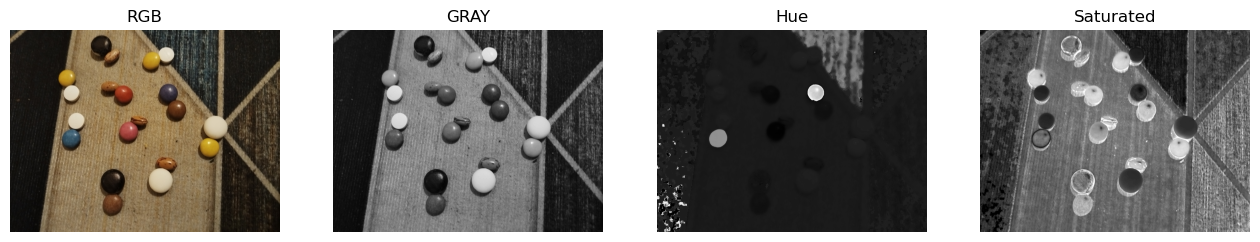

In [22]:
# display a sample and get dimensions
image_sample = cv2.imread("dev photos/IMG_20261105_200040.jpg")
print(f"image shape: {image_sample.shape}, image type: {image_sample.dtype}")

# convert from BGR to RGB
image_sample_RGB = cv2.cvtColor(image_sample, cv2.COLOR_BGR2RGB)
# convert from BGR to Grayscale
image_sample_GRAY = cv2.cvtColor(image_sample, cv2.COLOR_BGR2GRAY)
# convert from RGB to HSV
image_sample_HSV = cv2.cvtColor(image_sample_RGB, cv2.COLOR_RGB2HSV)

# display all of the images
fig, ax = plt.subplots(1, 4, figsize = (16, 3))

images = [image_sample_RGB, image_sample_GRAY, image_sample_HSV[..., 0], image_sample_HSV[..., 1]]
titles = ['RGB', 'GRAY', 'Hue', 'Saturated']

for a, img, title in zip(ax, images, titles):
    a.imshow(img, cmap=None if title == "RGB" else "gray")
    a.set_title(title)
    a.axis("off")

plt.show()

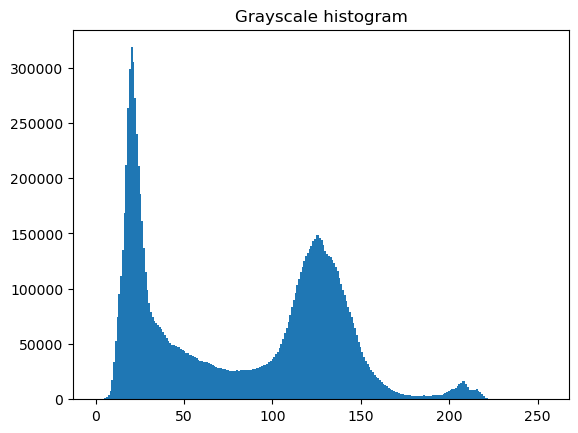

In [23]:
plt.hist(image_sample_GRAY.ravel(), bins=256, range=(0, 255))
plt.title("Grayscale histogram")
plt.show()

In [24]:
def load(path, width=100):
    """Load as BGR and shrink so experiments run fast

    Args:
        path : relative path for the images
        width (int, optional): the width on how much to shrink an image. Defaults to 100.
    Return:
        resized image
    """
    
    image = cv2.imread(path)
    h, w = image.shape[:2]
    scale = width / w
    return cv2.resize(image, (width, int(h * scale)))

In [25]:
def show_row(images, titles, figsize=(18, 4)):
    fig, ax = plt.subplots(1, len(images), figsize=figsize)
    for a, im, t in zip(ax, images, titles):
        a.imshow(im, cmap=None if im.ndim == 3 else "gray")
        a.set_title(t);a.axis("off")
    plt.show()

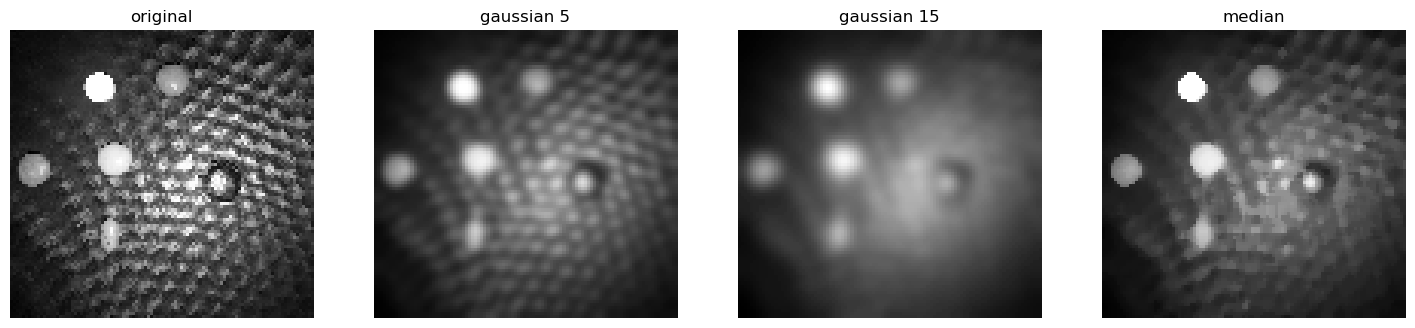

In [26]:
# blurring
image = load("dev photos/IMG_20261105_193647_edit_79067851294680.jpg")
gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)

blur_g5_kernel = (7,7)
blur_g15_kernel = (15, 15)

blur_g5 = cv2.GaussianBlur(gray, blur_g5_kernel, 0)
blur_g15 = cv2.GaussianBlur(gray, blur_g15_kernel, 0)
blur_m5 = cv2.medianBlur(gray, 5)
show_row([gray, blur_g5, blur_g15, blur_m5],
         ["original", "gaussian 5", "gaussian 15", "median"])

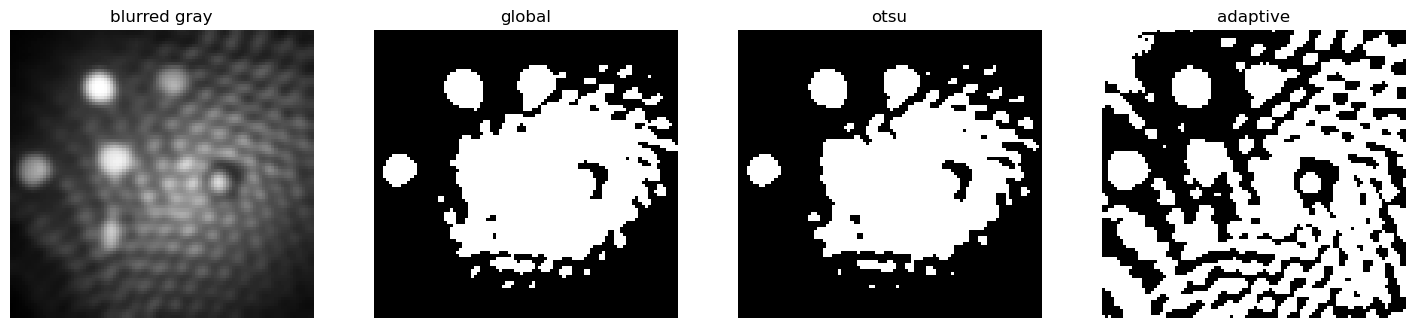

In [27]:
# threshold
mode = cv2.THRESH_BINARY

_, global_mask = cv2.threshold(blur_g5, 100, 255, mode)
_, otsu_mask = cv2.threshold(blur_g5, 0, 255, mode + cv2.THRESH_OTSU)
adaptive_mask = cv2.adaptiveThreshold(blur_g5, 255, cv2.ADAPTIVE_THRESH_GAUSSIAN_C, mode, 51, 5)

# TODO: Otsu on the saturation channel, then compare it to gray
# hsv = cv2.cvtColor(img, cv2.COLOR_BGR2HSV)
# sat = cv2.GaussianBlur(hsv[..., 1], (5, 5), 0)


show_row([blur_g5, global_mask, otsu_mask, adaptive_mask],
         ["blurred gray", "global", "otsu", "adaptive"])

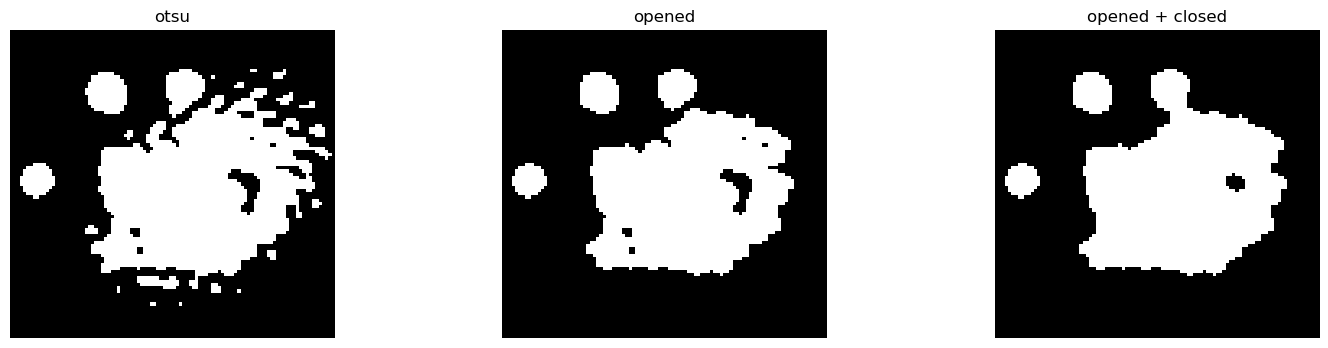

In [28]:
# morphology
kernel = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (5, 5))
opened = cv2.morphologyEx(otsu_mask, cv2.MORPH_OPEN, kernel)    # removes specks
closed = cv2.morphologyEx(opened, cv2.MORPH_CLOSE, kernel)      # fills holes
show_row([otsu_mask, opened, closed], ["otsu", "opened", "opened + closed"])

In [29]:
# comparison grid on all dev photos
dev_files = [
    "dev photos/IMG_20261105_193432_edit_78934497075824.jpg, dev photos/IMG_20261105_193647_edit_79067851294680.jpg,dev photos/IMG_20261105_194510_edit_79587777233909.jpg, dev photos/IMG_20261105_194859_edit_79841328727145.jpg, dev photos/IMG_20261105_200105.jpgdev photos/IMG_20261105_201012.jpg, "
]


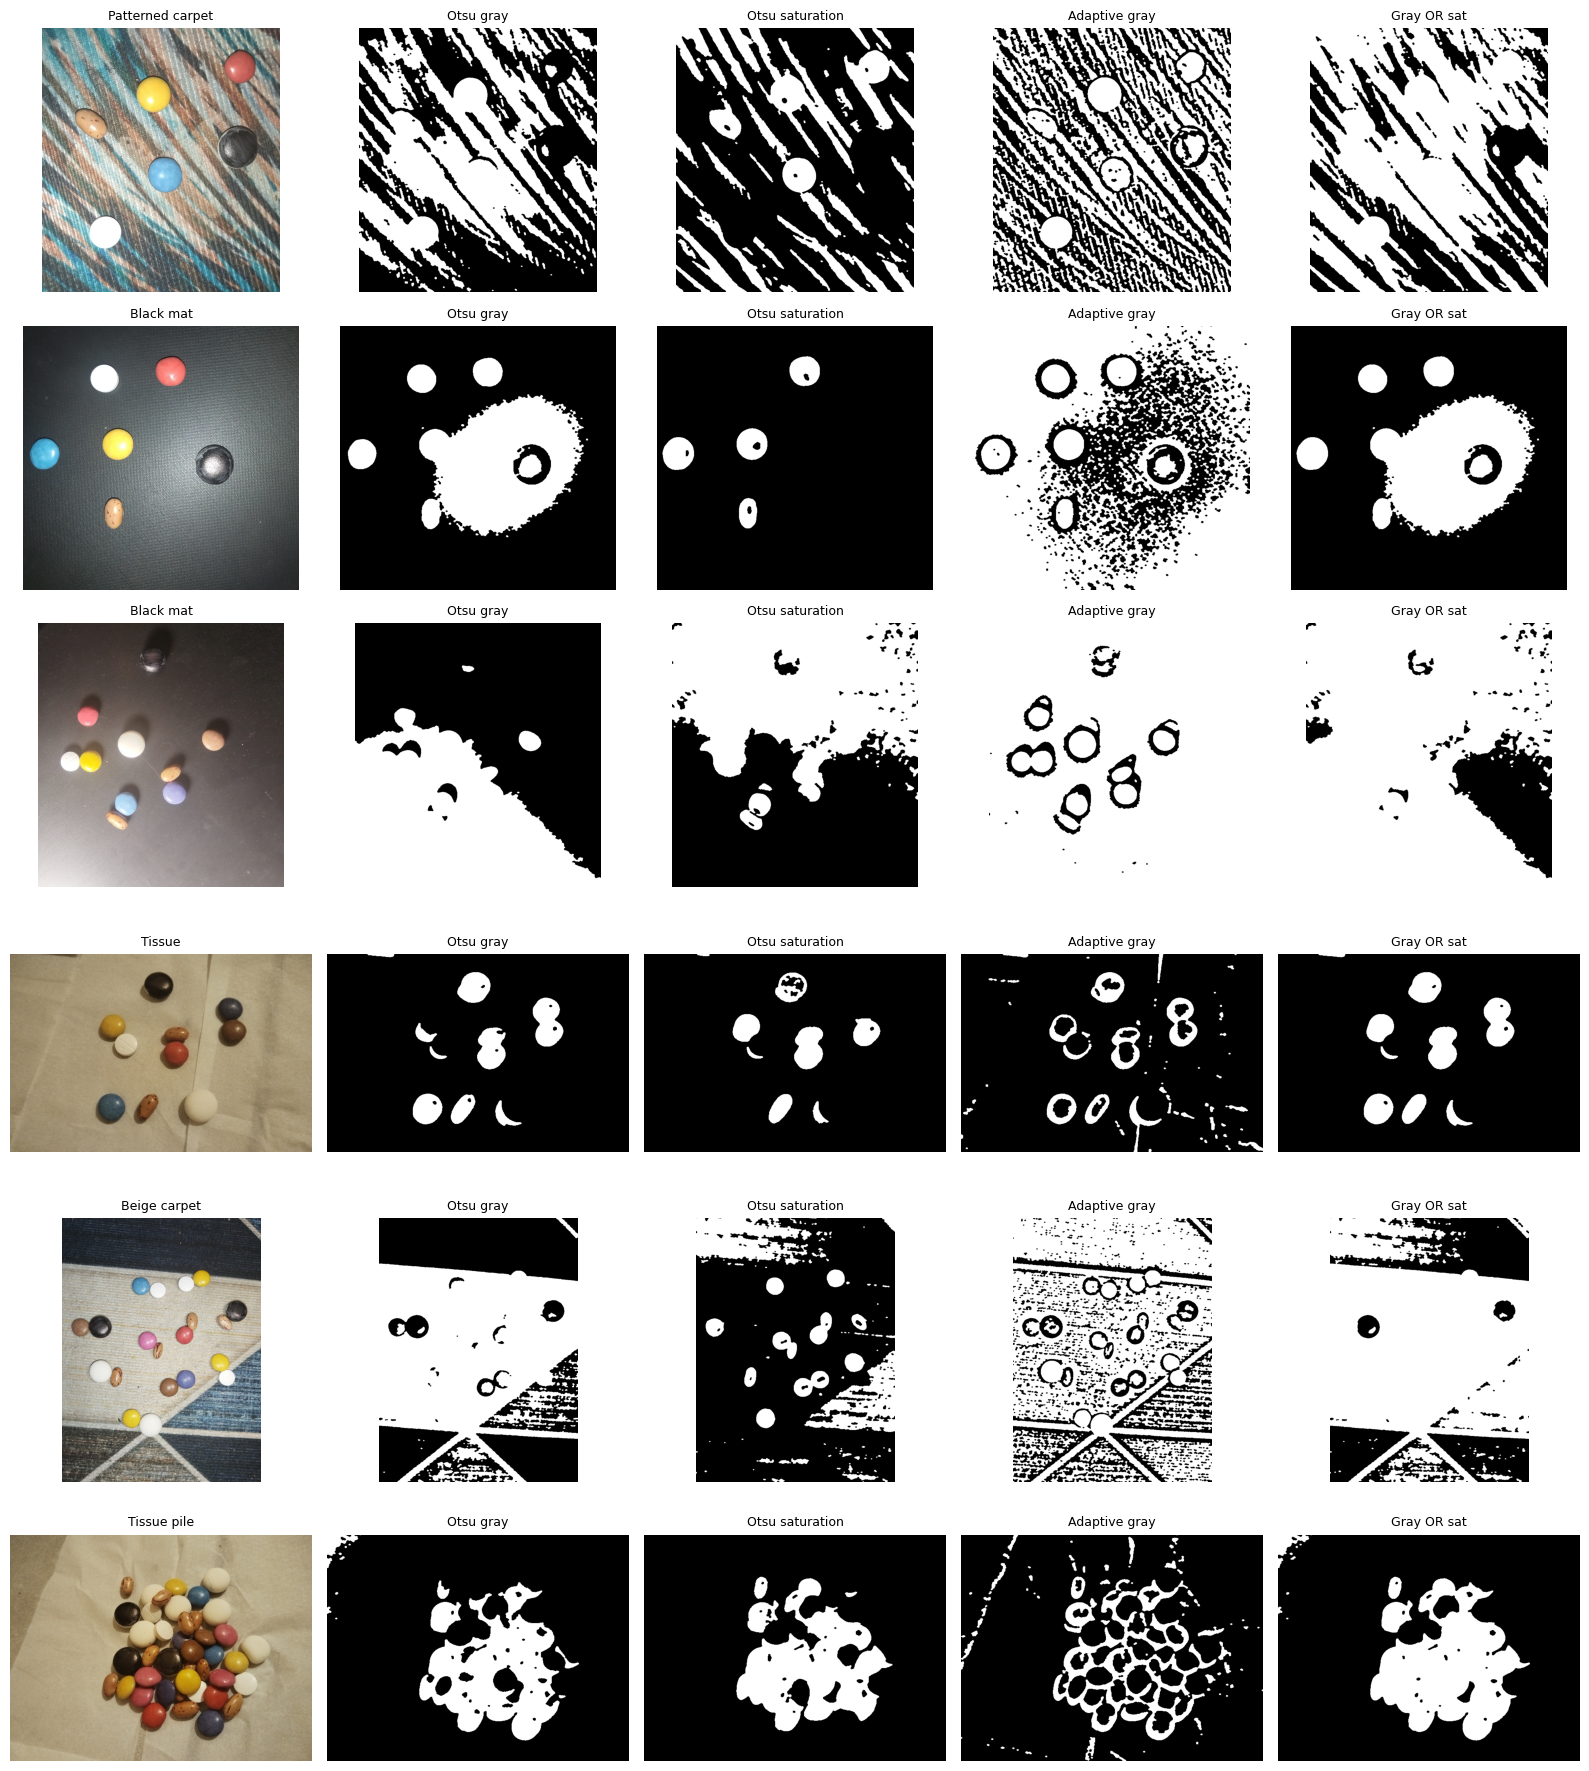

In [30]:
PHOTO_DIR = "dev photos/"
dev_files = [
    ("Patterned carpet", "IMG_20261105_193432_edit_78934497075824.jpg"),
    ("Black mat",        "IMG_20261105_193647_edit_79067851294680.jpg"),
    ("Black mat",        "IMG_20261105_194510_edit_79587777233909.jpg"),
    ("Tissue",           "IMG_20261105_194859_edit_79841328727145.jpg"),
    ("Beige carpet",     "IMG_20261105_200105.jpg"),
    ("Tissue pile",      "IMG_20261105_201012.jpg"),
]

def load(path, width=700):
    img = cv2.imread(path)
    h, w = img.shape[:2]
    return cv2.resize(img, (width, int(h * width / w)))

def border_is_bright(gray, frac=0.05):
    """Crude guess: is the background light? Looks at the image border."""
    b = max(1, int(min(gray.shape) * frac))
    border = np.concatenate([gray[:b].ravel(), gray[-b:].ravel(),
                             gray[:, :b].ravel(), gray[:, -b:].ravel()])
    return np.median(border) > 127

def clean(mask, k = 5):
    kernel = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (k, k))
    mask = cv2.morphologyEx(mask, cv2.MORPH_OPEN, kernel)
    return cv2.morphologyEx(mask, cv2.MORPH_CLOSE, kernel)

def make_masks(img):
    gray = cv2.GaussianBlur(cv2.cvtColor(img, cv2.COLOR_BGR2GRAY), (5,5), 0)
    sat  = cv2.GaussianBlur(cv2.cvtColor(img, cv2.COLOR_BGR2HSV)[..., 1], (5,5), 0)
    mode = cv2.THRESH_BINARY_INV if border_is_bright(gray) else cv2.THRESH_BINARY
    _, m_gray = cv2.threshold(gray, 0, 255, mode + cv2.THRESH_OTSU)
    _, m_sat  = cv2.threshold(sat, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
    m_adapt   = cv2.adaptiveThreshold(gray, 255, cv2.ADAPTIVE_THRESH_GAUSSIAN_C, mode, 51, 5)
    m_comb    = cv2.bitwise_or(m_gray, m_sat)
    return {"Otsu gray": clean(m_gray), "Otsu saturation": clean(m_sat),
            "Adaptive gray": clean(m_adapt), "Gray OR sat": clean(m_comb)}
    
def comparison_grid(files):
    n, ncols = len(files), 5
    fig, axes = plt.subplots(n, ncols, figsize=(3.2 * ncols, 3 * n))
    for r, (label, fname) in enumerate(files):
        img = load(PHOTO_DIR + fname)
        cells = [(cv2.cvtColor(img, cv2.COLOR_BGR2RGB), label)]
        cells += list(make_masks(img).items())[::1] if False else \
            [(m, name) for name, m in make_masks(img).items()]
        for c, (im, title) in enumerate(cells):
            ax = axes[r, c]
            ax.imshow(im, cmap = None if im.ndim == 3 else "gray")
            ax.set_title(title, fontsize=9)
            ax.axis("off")
    plt.tight_layout()
    plt.show()
    
comparison_grid(dev_files)